# 02 — Medallion Benchmark: Dataproc Lightning Engine (Base & Gluten/Velox C++ NQE)

This notebook benchmarks **Dataproc Lightning Engine** on Google Cloud Compute Engine (`2.3-debian12`, x86 `n2d-standard` + NVMe Local SSDs) across two sequential passes over the **exact same open GCS Parquet Bronze tables** (`gs://${BENCH_BUCKET}/bronze/${SCALE_PRESET}/`) used in Notebook `01`:

1. **Pass 1 — `spark_lightning_base` (`spark.dataproc.lightningEngine.runtime=default`):**
   Lightning Engine cluster with Native Query Execution (NQE) disabled (`nqe_enabled = False`).
2. **Pass 2 — `spark_lightning_nqe` (`spark.dataproc.lightningEngine.runtime=native`):**
   Lightning Engine with **Apache Gluten + Meta/Apache Velox C++ Native Query Execution** (`nqe_enabled = True`).

### Non-Negotiable Fairness Guardrails (`SPEC.md` §1.2 & §1.3)
- **Pure GCS Parquet I/O:** Zero BigQuery Spark connector reads or query pushdown. All Bronze reads and Silver/Gold writes execute purely against `gs://${BENCH_BUCKET}/...`.
- **x86 Hardware Parity:** `CLUSTER_LGT_NAME` uses identical VM family, vCPU count, RAM, and NVMe Local SSD configuration as `CLUSTER_STD_NAME` (`01`), differing only in `--engine=lightning`.
- **Shared Medallion Runner:** Executes `<repo_root>/scripts/run_spark_medallion.py` directly (via `gcloud dataproc jobs submit pyspark` or `in_cluster` `run_pipeline`) and logs via `scripts/metrics_helper.py` so `01` and `02` use one canonical implementation and US pricing model.

### Key Deliverables in This Notebook
- Sequential execution and telemetry logging (`results/live_runs/benchmark_runs.jsonl` & BigQuery `${DS_METRICS}.benchmark_runs`) correlated via `BENCH_RUN_ID` / `RUN_ID`, plus client-side `submit_wall_clock_sec` vs. warm in-cluster stage timers.
- **Fail-Closed Runtime & Plan Verification:** Verifies `lightning_runtime_conf` and native Gluten/Velox operators (`*Transformer`, `Velox*`, `NativeFileScan`) in Pass 2 Stage `1` before accepting results.
- **Catalyst vs. Gluten/Velox Physical Plan Audit:** Parses `df.explain("formatted")` across Stages `1`, `2A`, `2B`, and `3`, contrasting native C++ operators with the Stage `2B` `@F.udf` fallback boundary (`VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar`).
- **Parity, Speedup & Surcharge Break-Even:** Verifies 100% row-count parity and `±0.01%` `checksum_net_paid` tolerance, quantifies the Stage `2B` UDF penalty vs. Stage `2A`, and computes break-even speedup `%` using `scripts.metrics_helper.US_LIST_RATES` aligned with Notebook `04`.

## 1. Environment Configuration & Cross-Worker Setup

In [1]:
import json
import os
import re
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj: Any) -> None:
        print(obj)


def find_repo_root(start: Path | None = None) -> Path:
    '''Walk upward from cwd to locate the repository root containing SPEC.md.'''
    origin = (start or Path.cwd()).resolve()
    for candidate in (origin, *origin.parents):
        if (candidate / "SPEC.md").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing SPEC.md.")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.metrics_helper import (
    US_LIST_RATES,
    estimate_stage_list_cost_usd,
    infer_vcpus_from_machine_type,
    load_benchmark_runs,
    log_stage_metric,
    resolve_bench_config,
)


def run_gcloud_text(args: list[str]) -> str:
    '''Run gcloud and strip enterprise certificate-proxy preamble lines.'''
    proc = subprocess.run(["gcloud", *args], check=True, text=True, capture_output=True)
    lines = [ln for ln in proc.stdout.splitlines() if not ln.startswith("Created ")]
    return "\n".join(lines).strip()


def run_gcloud_json(args: list[str]) -> Any:
    '''Run gcloud --format=json and parse starting from the first JSON token.'''
    proc = subprocess.run(["gcloud", *args, "--format=json"], check=True, text=True, capture_output=True)
    raw = proc.stdout
    indices = [idx for idx in (raw.find("{"), raw.find("[")) if idx >= 0]
    if not indices:
        raise ValueError(f"Expected JSON output from gcloud {' '.join(args)}, got: {raw[:200]}")
    return json.loads(raw[min(indices):])


BENCH_CFG = resolve_bench_config(repo_root=REPO_ROOT)


def _cfg(key: str, default: str = "") -> str:
    val = os.environ.get(key)
    if val is not None and val.strip() != "":
        return val.strip()
    cfg_val = BENCH_CFG.get(key) if isinstance(BENCH_CFG, dict) else None
    if cfg_val is not None and str(cfg_val).strip() != "":
        return str(cfg_val).strip()
    return default


PROJECT_ID = _cfg("PROJECT_ID")
if not PROJECT_ID or PROJECT_ID == "your-gcp-project-id":
    raise ValueError("PROJECT_ID must be set in .env or environment (cannot be placeholder 'your-gcp-project-id').")

PROJECT_NUMBER = _cfg("PROJECT_NUMBER")
if not PROJECT_NUMBER:
    PROJECT_NUMBER = run_gcloud_text(["projects", "describe", PROJECT_ID, "--format=value(projectNumber)"])
if not PROJECT_NUMBER:
    raise ValueError("Unable to resolve PROJECT_NUMBER from environment or gcloud.")

BENCH_BUCKET = (_cfg("BENCH_BUCKET") or f"lakehouse-bench-{PROJECT_NUMBER}").removeprefix("gs://").rstrip("/")

SCALE_PRESET = _cfg("SCALE_PRESET", "small_1g")
if SCALE_PRESET not in {"small_1g", "medium_100g", "large_500g"}:
    raise ValueError(f"Unsupported SCALE_PRESET='{SCALE_PRESET}'. Expected small_1g, medium_100g, or large_500g.")

DATAPROC_REGION = _cfg("DATAPROC_REGION", "us-central1")
DATAPROC_ZONE = _cfg("DATAPROC_ZONE", "us-central1-a")
DATAPROC_IMAGE_VERSION = _cfg("DATAPROC_IMAGE_VERSION", "2.3-debian12")
CLUSTER_LGT_NAME = _cfg("CLUSTER_LGT_NAME", "bench-spark-lightning-x86")
MASTER_MACHINE_TYPE = _cfg("MASTER_MACHINE_TYPE", "n2d-standard-4")
WORKER_MACHINE_TYPE = _cfg("WORKER_MACHINE_TYPE", "n2d-standard-8")
NUM_PRIMARY_WORKERS = int(_cfg("NUM_PRIMARY_WORKERS", "2"))
NUM_WORKER_LOCAL_SSDS = int(_cfg("NUM_WORKER_LOCAL_SSDS", "1"))
WORKER_VCPUS_PER_NODE = infer_vcpus_from_machine_type(WORKER_MACHINE_TYPE)
TOTAL_WORKER_VCPUS = int(_cfg("TOTAL_WORKER_VCPUS") or (WORKER_VCPUS_PER_NODE * NUM_PRIMARY_WORKERS))

RUN_PYTHON_UDF_STAGE = _cfg("RUN_PYTHON_UDF_STAGE", "true").lower() in {"1", "true", "yes"}
UDF_MAX_SAMPLE_ROWS = int(_cfg("UDF_MAX_SAMPLE_ROWS", "500000"))
DS_METRICS = _cfg("DS_METRICS", "bench_metrics")
_write_bq_raw = _cfg("WRITE_TO_BQ_METRICS") or _cfg("WRITE_METRICS_TO_BQ", "true")
WRITE_METRICS_TO_BQ = _write_bq_raw.lower() in {"1", "true", "yes"}

EXECUTION_MODE = _cfg("SPARK_EXECUTION_MODE").lower()
if not EXECUTION_MODE:
    try:
        from pyspark.sql import SparkSession

        EXECUTION_MODE = "in_cluster" if SparkSession.getActiveSession() is not None else "dataproc_submit"
    except ImportError:
        EXECUTION_MODE = "dataproc_submit"
if EXECUTION_MODE not in {"dataproc_submit", "in_cluster"}:
    raise ValueError(f"Unsupported SPARK_EXECUTION_MODE='{EXECUTION_MODE}'. Expected dataproc_submit or in_cluster.")

RUN_ID = (
    _cfg("BENCH_RUN_ID")
    or _cfg("RUN_ID")
    or f"{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}_{SCALE_PRESET}"
)

RUNNER_SCRIPT = REPO_ROOT / "scripts" / "run_spark_medallion.py"
if not RUNNER_SCRIPT.is_file():
    raise FileNotFoundError(f"Shared PySpark runner missing at {RUNNER_SCRIPT}.")

LIVE_JSONL_PATH = REPO_ROOT / "results" / "live_runs" / "benchmark_runs.jsonl"
SUBMIT_TIMINGS_JSONL_PATH = LIVE_JSONL_PATH.with_name("spark_lightning_submit_timings.jsonl")

config_summary = pd.DataFrame(
    [
        ("RUN_ID", RUN_ID),
        ("SCALE_PRESET", SCALE_PRESET),
        ("BENCH_BUCKET", f"gs://{BENCH_BUCKET}"),
        ("CLUSTER_LGT_NAME", CLUSTER_LGT_NAME),
        ("DATAPROC_REGION / ZONE", f"{DATAPROC_REGION} / {DATAPROC_ZONE}"),
        ("DATAPROC_IMAGE_VERSION", DATAPROC_IMAGE_VERSION),
        ("WORKER_MACHINE_TYPE", f"{WORKER_MACHINE_TYPE} ({WORKER_VCPUS_PER_NODE} vCPUs/node)"),
        ("NUM_PRIMARY_WORKERS", NUM_PRIMARY_WORKERS),
        ("TOTAL_WORKER_VCPUS", TOTAL_WORKER_VCPUS),
        ("NUM_WORKER_LOCAL_SSDS", NUM_WORKER_LOCAL_SSDS),
        ("RUN_PYTHON_UDF_STAGE", RUN_PYTHON_UDF_STAGE),
        ("UDF_MAX_SAMPLE_ROWS", UDF_MAX_SAMPLE_ROWS),
        ("WRITE_METRICS_TO_BQ", WRITE_METRICS_TO_BQ),
        ("EXECUTION_MODE", EXECUTION_MODE),
        ("RUNNER_SCRIPT", str(RUNNER_SCRIPT.relative_to(REPO_ROOT))),
    ],
    columns=["Setting", "Value"],
)
display(config_summary)

,Setting,Value
0,RUN_ID,20261116T103813Z_large_500g
1,SCALE_PRESET,large_500g
2,BENCH_BUCKET,gs://lakehouse-bench-
3,CLUSTER_LGT_NAME,bench-spark-lightning-x86
4,DATAPROC_REGION / ZONE,us-central1 / us-central1-a
5,DATAPROC_IMAGE_VERSION,2.3-debian12
6,WORKER_MACHINE_TYPE,n2d-standard-16 (16 vCPUs/node)
7,NUM_PRIMARY_WORKERS,4
8,TOTAL_WORKER_VCPUS,64
9,NUM_WORKER_LOCAL_SSDS,2


## 2. Pre-Flight Hardware, Engine & Bronze GCS Parquet Readiness

Verifies two invariants before starting any timed run:
1. `${CLUSTER_LGT_NAME}` is `RUNNING` with `LIGHTNING` engine enabled, image `2.3-debian12`, x86 workers matching `WORKER_MACHINE_TYPE × NUM_PRIMARY_WORKERS`, and `NUM_WORKER_LOCAL_SSDS` NVMe disks.
2. All 8 Bronze TPC-DS Parquet folders exist under `gs://${BENCH_BUCKET}/bronze/${SCALE_PRESET}/<table>/`.

In [2]:
REQUIRED_BRONZE_TABLES = (
    "store_sales",
    "store_returns",
    "web_sales",
    "web_returns",
    "customer",
    "customer_demographics",
    "item",
    "date_dim",
)


def verify_lightning_cluster() -> dict[str, Any]:
    '''Validate CLUSTER_LGT_NAME exists, is RUNNING, and uses Lightning + x86 parity.'''
    cluster = run_gcloud_json(
        [
            "dataproc",
            "clusters",
            "describe",
            CLUSTER_LGT_NAME,
            f"--region={DATAPROC_REGION}",
            f"--project={PROJECT_ID}",
        ]
    )
    state = cluster.get("status", {}).get("state", "UNKNOWN")
    cfg = cluster.get("config", {})
    soft_cfg = cfg.get("softwareConfig", {})
    soft_props = soft_cfg.get("properties", {})
    engine = str(cfg.get("engine") or soft_props.get("dataproc:dataproc.engine", "DEFAULT")).upper()
    image_version = soft_cfg.get("imageVersion", "")
    worker_cfg = cfg.get("workerConfig", {})
    machine_uri = worker_cfg.get("machineTypeUri", "")
    machine_short = machine_uri.rsplit("/", 1)[-1] if machine_uri else ""
    num_workers = int(worker_cfg.get("numInstances", 0))
    num_ssds = int(worker_cfg.get("diskConfig", {}).get("numLocalSsds", 0))

    assert state == "RUNNING", f"Cluster {CLUSTER_LGT_NAME} state is '{state}', expected 'RUNNING'."
    assert engine == "LIGHTNING", f"Cluster {CLUSTER_LGT_NAME} engine is '{engine}', expected 'LIGHTNING'."
    assert not machine_short.startswith(("t2a-", "c4a-")), (
        f"ARM machine type '{machine_short}' violates x86 hardware parity (SPEC.md §1.3)."
    )
    assert machine_short == WORKER_MACHINE_TYPE, (
        f"Worker machine mismatch: cluster has '{machine_short}', expected '{WORKER_MACHINE_TYPE}'."
    )
    assert num_workers == NUM_PRIMARY_WORKERS, (
        f"Worker count mismatch: cluster has {num_workers}, expected {NUM_PRIMARY_WORKERS}."
    )
    assert num_ssds == NUM_WORKER_LOCAL_SSDS, (
        f"Local SSD mismatch: cluster has {num_ssds}, expected {NUM_WORKER_LOCAL_SSDS}."
    )
    return {
        "cluster_name": CLUSTER_LGT_NAME,
        "state": state,
        "engine": engine,
        "image_version": image_version,
        "worker_machine_type": machine_short,
        "num_workers": num_workers,
        "num_local_ssds": num_ssds,
    }


def verify_bronze_parquet_tables() -> pd.DataFrame:
    '''Confirm all 8 TPC-DS Bronze Parquet prefixes exist in GCS for SCALE_PRESET.'''
    from google.cloud import storage

    client = storage.Client(project=PROJECT_ID)
    bucket = client.bucket(BENCH_BUCKET)
    rows: list[dict[str, Any]] = []
    missing: list[str] = []
    for table in REQUIRED_BRONZE_TABLES:
        prefix = f"bronze/{SCALE_PRESET}/{table}/"
        blobs = [
            b
            for b in bucket.list_blobs(prefix=prefix)
            if not b.name.endswith("/") and (b.name.endswith(".parquet") or (b.size or 0) > 0)
        ]
        total_bytes = sum(int(b.size or 0) for b in blobs)
        if not blobs:
            missing.append(f"gs://{BENCH_BUCKET}/{prefix}")
        rows.append(
            {
                "table": table,
                "gcs_prefix": f"gs://{BENCH_BUCKET}/{prefix}",
                "parquet_objects": len(blobs),
                "total_mb": round(total_bytes / (1024 * 1024), 2),
            }
        )
    if missing:
        raise FileNotFoundError(
            "Missing Bronze Parquet tables (run notebooks/00_data_copy_ingestion.ipynb first): "
            + ", ".join(missing)
        )
    return pd.DataFrame(rows)


if EXECUTION_MODE == "dataproc_submit":
    cluster_audit = verify_lightning_cluster()
    display(pd.DataFrame([cluster_audit]))
else:
    print(f"EXECUTION_MODE={EXECUTION_MODE}: skipping remote cluster describe.")

bronze_audit_df = verify_bronze_parquet_tables()
display(bronze_audit_df)

,cluster_name,state,engine,image_version,worker_machine_type,num_workers,num_local_ssds
0,bench-spark-lightning-x86,RUNNING,LIGHTNING,2.3.38-debian12,n2d-standard-16,4,2


,table,gcs_prefix,parquet_objects,total_mb
0,store_sales,gs://lakehouse-bench-/bronze/large...,1758,54824.80
1,store_returns,gs://lakehouse-bench-/bronze/large...,468,10703.69
2,web_sales,gs://lakehouse-bench-/bronze/large...,1289,27069.99
3,web_returns,gs://lakehouse-bench-/bronze/large...,104,3075.10
4,customer,gs://lakehouse-bench-/bronze/large...,166,3462.68
5,customer_demographics,gs://lakehouse-bench-/bronze/large...,5,12.93
6,item,gs://lakehouse-bench-/bronze/large...,1,44.03
7,date_dim,gs://lakehouse-bench-/bronze/large...,1,2.46


## 3. Shared PySpark Runner Submission & Client/Cluster Timing Helpers

- Submits `<repo_root>/scripts/run_spark_medallion.py` directly (`dataproc_submit` via `gcloud dataproc jobs submit pyspark`, or `in_cluster` via `scripts.run_spark_medallion.run_pipeline`).
- Captures client-side end-to-end submission time (`submit_wall_clock_sec`, including Dataproc job submission & Spark session setup) separately from the runner's warm in-cluster stage timers (`wall_clock_sec`).
- **Flag syntax note:** `gcloud dataproc jobs submit pyspark --properties` takes `KEY=VALUE` **without** a `spark:` prefix:
  - Pass 1: `--properties=spark.dataproc.lightningEngine.runtime=default`
  - Pass 2: `--properties=spark.dataproc.lightningEngine.runtime=native`

In [3]:
def build_runner_cli_args(engine_variant: str, metrics_gcs_uri: str) -> list[str]:
    '''Build canonical CLI arguments accepted by scripts/run_spark_medallion.py.'''
    return [
        "--engine-variant",
        engine_variant,
        "--scale-preset",
        SCALE_PRESET,
        "--bench-bucket",
        BENCH_BUCKET,
        "--run-id",
        RUN_ID,
        "--worker-machine-type",
        WORKER_MACHINE_TYPE,
        "--total-worker-vcpus",
        str(TOTAL_WORKER_VCPUS),
        "--run-python-udf",
        "true" if RUN_PYTHON_UDF_STAGE else "false",
        "--udf-max-sample-rows",
        str(UDF_MAX_SAMPLE_ROWS),
        "--metrics-gcs-uri",
        metrics_gcs_uri,
    ]


def read_gcs_json(gcs_uri: str) -> dict[str, Any]:
    '''Download and parse a JSON object from gs://bucket/path.'''
    from google.cloud import storage

    if not gcs_uri.startswith("gs://"):
        raise ValueError(f"Expected gs:// URI, got '{gcs_uri}'.")
    bucket_name, blob_path = gcs_uri.removeprefix("gs://").split("/", 1)
    client = storage.Client(project=PROJECT_ID)
    raw = client.bucket(bucket_name).blob(blob_path).download_as_text(encoding="utf-8")
    return json.loads(raw)


def _extract_stdout_payload(stdout: str) -> dict[str, Any] | None:
    begin = "BENCHMARK_METRICS_JSON_BEGIN"
    end = "BENCHMARK_METRICS_JSON_END"
    if begin in stdout and end in stdout:
        body = stdout.split(begin, 1)[1].split(end, 1)[0].strip()
        return json.loads(body)
    return None


def submit_lightning_pass(engine_variant: str, runtime_mode: str) -> dict[str, Any]:
    '''Execute one Lightning Engine Medallion pass and return parsed telemetry, plans, and submit timer.'''
    if not RUNNER_SCRIPT.is_file():
        raise FileNotFoundError(f"Shared runner not found: {RUNNER_SCRIPT}")
    metrics_gcs_uri = f"gs://{BENCH_BUCKET}/metrics/{RUN_ID}/{engine_variant}.json"
    cli_args = build_runner_cli_args(engine_variant, metrics_gcs_uri)
    print(
        f"Executing {engine_variant} (runtime={runtime_mode}, mode={EXECUTION_MODE}) "
        f"via {RUNNER_SCRIPT.relative_to(REPO_ROOT)} -> {metrics_gcs_uri}"
    )

    submit_t0 = time.time()
    if EXECUTION_MODE == "in_cluster":
        from pyspark.sql import SparkSession
        from scripts.run_spark_medallion import run_pipeline, write_json_to_hadoop_uri

        spark = SparkSession.builder.getOrCreate()
        active_runtime = spark.conf.get("spark.dataproc.lightningEngine.runtime", "unset")
        if runtime_mode == "native" and active_runtime != "native":
            raise RuntimeError(
                f"in_cluster session reports lightningEngine.runtime={active_runtime!r}; "
                "cannot benchmark 'native'. Run with EXECUTION_MODE='dataproc_submit'."
            )
        if runtime_mode != "native" and active_runtime == "native":
            raise RuntimeError(
                f"in_cluster session reports lightningEngine.runtime={active_runtime!r}; "
                "cannot benchmark non-native pass. Run with EXECUTION_MODE='dataproc_submit'."
            )
        payload = run_pipeline(
            spark=spark,
            engine_variant=engine_variant,
            scale_preset=SCALE_PRESET,
            bronze_base_uri=f"gs://{BENCH_BUCKET}/bronze/{SCALE_PRESET}",
            silver_base_uri=f"gs://{BENCH_BUCKET}/silver/{SCALE_PRESET}/{engine_variant}",
            gold_base_uri=f"gs://{BENCH_BUCKET}/gold/{SCALE_PRESET}/{engine_variant}",
            run_id=RUN_ID,
            worker_machine_type=WORKER_MACHINE_TYPE,
            total_worker_vcpus=TOTAL_WORKER_VCPUS,
            run_python_udf=RUN_PYTHON_UDF_STAGE,
            udf_max_sample_rows=UDF_MAX_SAMPLE_ROWS,
        )
        write_json_to_hadoop_uri(spark, metrics_gcs_uri, payload)
        submit_t1 = time.time()
    else:
        # NOTE: `gcloud dataproc jobs submit pyspark --properties` takes KEY=VALUE WITHOUT `spark:` prefix.
        cmd = [
            "gcloud",
            "dataproc",
            "jobs",
            "submit",
            "pyspark",
            str(RUNNER_SCRIPT),
            f"--project={PROJECT_ID}",
            f"--region={DATAPROC_REGION}",
            f"--cluster={CLUSTER_LGT_NAME}",
            f"--properties=spark.dataproc.lightningEngine.runtime={runtime_mode}",
            "--",
            *cli_args,
        ]
        proc = subprocess.run(cmd, text=True, capture_output=True)
        submit_t1 = time.time()
        if proc.returncode != 0:
            print(proc.stdout[-4000:])
            print(proc.stderr[-4000:], file=sys.stderr)
            raise RuntimeError(f"Dataproc PySpark job failed for {engine_variant} (exit={proc.returncode}).")
        try:
            payload = read_gcs_json(metrics_gcs_uri)
        except Exception as gcs_err:
            payload = _extract_stdout_payload(proc.stdout)
            if payload is None:
                raise RuntimeError(
                    f"Failed to read {metrics_gcs_uri} and no stdout fallback found."
                ) from gcs_err

    payload["submit_wall_clock_sec"] = round(submit_t1 - submit_t0, 4)
    payload.setdefault("metrics_gcs_uri", metrics_gcs_uri)
    return payload

## 4. Pass 1 — Base Lightning Engine (`spark_lightning_base`, `runtime=default`)

Submits `scripts/run_spark_medallion.py` to `${CLUSTER_LGT_NAME}` with:
`--properties="spark.dataproc.lightningEngine.runtime=default"` (`nqe_enabled = False`).

In [4]:
def validate_base_pass_payload(payload: dict[str, Any]) -> str:
    '''Fail closed if Pass 1 payload omits lightning_runtime_conf or ran with runtime=native.'''
    if "lightning_runtime_conf" not in payload:
        raise KeyError("Pass 1 payload missing required key 'lightning_runtime_conf'.")
    runtime_conf = str(payload["lightning_runtime_conf"])
    if runtime_conf == "native":
        raise AssertionError(
            "Pass 1 (spark_lightning_base) expected non-native runtime, "
            f"got lightning_runtime_conf={runtime_conf!r}."
        )
    return runtime_conf


base_payload = submit_lightning_pass(
    engine_variant="spark_lightning_base",
    runtime_mode="default",
)
base_runtime_conf = validate_base_pass_payload(base_payload)
base_records = base_payload["records"]
base_plans = base_payload.get("plans", {})
base_submit_wall_sec = float(base_payload.get("submit_wall_clock_sec") or 0.0)
base_stage_sum_sec = sum(float(r["wall_clock_sec"]) for r in base_records)

print(
    f"Pass 1 complete: engine_variant=spark_lightning_base | "
    f"lightning_runtime_conf={base_runtime_conf!r} | stages={len(base_records)} | "
    f"active_stage_sum_sec={base_stage_sum_sec:.2f}s | submit_wall_clock_sec={base_submit_wall_sec:.2f}s"
)
base_df_preview = pd.DataFrame(base_records)
base_cols = [
    c
    for c in ("stage_id", "wall_clock_sec", "vcpu_seconds", "output_row_count", "checksum_net_paid", "nqe_enabled")
    if c in base_df_preview.columns
]
display(base_df_preview[base_cols])

Executing spark_lightning_base (runtime=default, mode=dataproc_submit) via scripts/run_spark_medallion.py -> gs://lakehouse-bench-<project-number>/metrics/20261116T103813Z_large_500g/spark_lightning_base.json


Pass 1 complete: engine_variant=spark_lightning_base | lightning_runtime_conf='default' | stages=4 | active_stage_sum_sec=340.41s | submit_wall_clock_sec=384.82s


,stage_id,wall_clock_sec,vcpu_seconds,output_row_count,checksum_net_paid,nqe_enabled
0,stage1_bronze_to_silver,140.9626,9021.6064,1014392792,1.841730e+12,False
1,stage2a_silver_vectorized,83.1734,5323.0976,1014392792,1.841730e+12,False
2,stage2b_silver_udf,26.4726,1694.2464,50660213,9.200404e+10,False
3,stage3_silver_to_gold,89.8031,5747.3984,28068,1.837184e+12,False


## 5. Pass 2 — Lightning Engine + Gluten/Velox C++ NQE (`spark_lightning_nqe`, `runtime=native`)

Submits `scripts/run_spark_medallion.py` to `${CLUSTER_LGT_NAME}` with:
`--properties="spark.dataproc.lightningEngine.runtime=native"` (`nqe_enabled = True`), and fails closed unless both `lightning_runtime_conf == "native"` and Stage `1` contains Gluten/Velox native plan operators.

In [5]:
NATIVE_PLAN_ASSERT_TOKENS = ("Transformer", "Velox", "NativeFileScan")


def validate_nqe_pass_payload(payload: dict[str, Any]) -> str:
    '''Fail closed unless Pass 2 ran with runtime=native and Stage 1 offloaded to Gluten/Velox.'''
    if "lightning_runtime_conf" not in payload:
        raise KeyError("Pass 2 payload missing required key 'lightning_runtime_conf'.")
    runtime_conf = str(payload["lightning_runtime_conf"])
    if runtime_conf != "native":
        raise AssertionError(
            "Pass 2 (spark_lightning_nqe) failed runtime verification: "
            f"expected lightning_runtime_conf == 'native', got {runtime_conf!r}."
        )
    plans = payload.get("plans", {})
    stage1_plan = plans.get("stage1_bronze_to_silver", "")
    if not any(tok in stage1_plan for tok in NATIVE_PLAN_ASSERT_TOKENS):
        raise AssertionError(
            "Pass 2 (spark_lightning_nqe) Stage 1 formatted physical plan contains zero native "
            f"Gluten/Velox tokens ({', '.join(NATIVE_PLAN_ASSERT_TOKENS)}). "
            "Verify --properties=spark.dataproc.lightningEngine.runtime=native took effect on CLUSTER_LGT_NAME."
        )
    return runtime_conf


nqe_payload = submit_lightning_pass(
    engine_variant="spark_lightning_nqe",
    runtime_mode="native",
)
nqe_runtime_conf = validate_nqe_pass_payload(nqe_payload)
nqe_records = nqe_payload["records"]
nqe_plans = nqe_payload.get("plans", {})
nqe_submit_wall_sec = float(nqe_payload.get("submit_wall_clock_sec") or 0.0)
nqe_stage_sum_sec = sum(float(r["wall_clock_sec"]) for r in nqe_records)

print(
    f"Pass 2 complete: engine_variant=spark_lightning_nqe | "
    f"lightning_runtime_conf={nqe_runtime_conf!r} | stages={len(nqe_records)} | "
    f"active_stage_sum_sec={nqe_stage_sum_sec:.2f}s | submit_wall_clock_sec={nqe_submit_wall_sec:.2f}s"
)
nqe_df_preview = pd.DataFrame(nqe_records)
nqe_cols = [
    c
    for c in (
        "stage_id",
        "wall_clock_sec",
        "vcpu_seconds",
        "output_row_count",
        "checksum_net_paid",
        "nqe_enabled",
        "nqe_fallback_note",
    )
    if c in nqe_df_preview.columns
]
display(nqe_df_preview[nqe_cols])

Executing spark_lightning_nqe (runtime=native, mode=dataproc_submit) via scripts/run_spark_medallion.py -> gs://lakehouse-bench-<project-number>/metrics/20261116T103813Z_large_500g/spark_lightning_nqe.json


Pass 2 complete: engine_variant=spark_lightning_nqe | lightning_runtime_conf='native' | stages=4 | active_stage_sum_sec=282.55s | submit_wall_clock_sec=324.56s


,stage_id,wall_clock_sec,vcpu_seconds,output_row_count,checksum_net_paid,nqe_enabled,nqe_fallback_note
0,stage1_bronze_to_silver,112.9075,7226.0800,1014392792,1.841730e+12,True,
1,stage2a_silver_vectorized,73.8649,4727.3536,1014392792,1.841730e+12,True,
2,stage2b_silver_udf,26.0853,1669.4592,50660213,9.200404e+10,True,JVM/Python UDF fallback detected: VeloxColumna...
3,stage3_silver_to_gold,69.6902,4460.1728,28068,1.837184e+12,True,


## 6. Persist Unified Telemetry (`results/live_runs/benchmark_runs.jsonl` & BigQuery)

Persists all stage records for both `spark_lightning_base` (`nqe_enabled=False`) and `spark_lightning_nqe` (`nqe_enabled=True`) strictly via `scripts.metrics_helper.log_stage_metric(...)` (preserving the canonical 21-field JSONL/BigQuery schema), and logs client-side `submit_wall_clock_sec` alongside in-cluster stage sums into a companion `spark_lightning_submit_timings.jsonl` record.

In [6]:
def persist_lightning_telemetry(
    *,
    b_payload: dict[str, Any],
    n_payload: dict[str, Any],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Log all stage metrics via scripts.metrics_helper and record pass-level submit wall-clock summary.'''
    logged_rows: list[dict[str, Any]] = []
    boundary_rows: list[dict[str, Any]] = []

    for expected_nqe, payload in ((False, b_payload), (True, n_payload)):
        raw_records = payload["records"]
        stage_sum = 0.0
        for rec in raw_records:
            wall = float(rec["end_epoch_sec"]) - float(rec["start_epoch_sec"])
            stage_sum += wall
            est_cost = rec.get("est_list_cost_usd")
            if est_cost is None:
                est_cost = estimate_stage_list_cost_usd(
                    engine_variant=rec["engine_variant"],
                    wall_clock_sec=wall,
                    worker_machine_type=rec.get("worker_machine_type", WORKER_MACHINE_TYPE),
                    total_worker_vcpus=int(rec.get("total_worker_vcpus", TOTAL_WORKER_VCPUS)),
                    num_worker_local_ssds=NUM_WORKER_LOCAL_SSDS,
                )
            logged_rows.append(
                log_stage_metric(
                    run_id=rec.get("run_id", RUN_ID),
                    scale_preset=rec.get("scale_preset", SCALE_PRESET),
                    engine_variant=rec["engine_variant"],
                    storage_backend=rec.get("storage_backend", "gcs_parquet"),
                    stage_id=rec["stage_id"],
                    start_epoch_sec=float(rec["start_epoch_sec"]),
                    end_epoch_sec=float(rec["end_epoch_sec"]),
                    output_row_count=int(rec["output_row_count"]),
                    checksum_net_paid=rec.get("checksum_net_paid"),
                    worker_machine_type=rec.get("worker_machine_type", WORKER_MACHINE_TYPE),
                    total_worker_vcpus=int(rec.get("total_worker_vcpus", TOTAL_WORKER_VCPUS)),
                    bq_slot_cap=rec.get("bq_slot_cap"),
                    bq_total_slot_ms=rec.get("bq_total_slot_ms"),
                    bq_bytes_processed=rec.get("bq_bytes_processed"),
                    nqe_enabled=expected_nqe,
                    nqe_fallback_note=str(rec.get("nqe_fallback_note", "")),
                    est_list_cost_usd=est_cost,
                    sample_fraction=float(rec.get("sample_fraction", 1.0)),
                    jsonl_path=LIVE_JSONL_PATH,
                    write_to_bq=WRITE_METRICS_TO_BQ,
                    project_id=PROJECT_ID,
                    ds_metrics=DS_METRICS,
                )
            )

        submit_wall = payload.get("submit_wall_clock_sec")
        submit_val = float(submit_wall) if submit_wall is not None else None
        overhead_val = round(submit_val - stage_sum, 4) if submit_val is not None else None
        b_row = {
            "run_id": payload.get("run_id", RUN_ID),
            "timestamp_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "scale_preset": payload.get("scale_preset", SCALE_PRESET),
            "engine_variant": payload.get("engine_variant") or raw_records[0]["engine_variant"],
            "lightning_runtime_conf": payload.get("lightning_runtime_conf"),
            "active_stage_sum_sec": round(stage_sum, 4),
            "submit_wall_clock_sec": round(submit_val, 4) if submit_val is not None else None,
            "client_submit_overhead_sec": overhead_val,
        }
        boundary_rows.append(b_row)

    SUBMIT_TIMINGS_JSONL_PATH.parent.mkdir(parents=True, exist_ok=True)
    with SUBMIT_TIMINGS_JSONL_PATH.open("a", encoding="utf-8") as fh:
        for b_row in boundary_rows:
            fh.write(json.dumps(b_row) + "\n")

    return pd.DataFrame(logged_rows), pd.DataFrame(boundary_rows)


logged_df, pass_boundary_df = persist_lightning_telemetry(
    b_payload=base_payload,
    n_payload=nqe_payload,
)
_display_jsonl = LIVE_JSONL_PATH.relative_to(REPO_ROOT) if LIVE_JSONL_PATH.is_relative_to(REPO_ROOT) else LIVE_JSONL_PATH
_display_submit = (
    SUBMIT_TIMINGS_JSONL_PATH.relative_to(REPO_ROOT)
    if SUBMIT_TIMINGS_JSONL_PATH.is_relative_to(REPO_ROOT)
    else SUBMIT_TIMINGS_JSONL_PATH
)
print(
    f"Persisted {len(logged_df)} 21-field stage records to {_display_jsonl} "
    f"(write_to_bq={WRITE_METRICS_TO_BQ}) and pass-level submit timings to {_display_submit}."
)
display(
    logged_df[
        [
            "engine_variant",
            "stage_id",
            "wall_clock_sec",
            "vcpu_seconds",
            "output_row_count",
            "checksum_net_paid",
            "nqe_enabled",
            "est_list_cost_usd",
        ]
    ]
)
display(pass_boundary_df)

Persisted 8 21-field stage records to results/live_runs/benchmark_runs.jsonl (write_to_bq=True) and pass-level submit timings to results/live_runs/spark_lightning_submit_timings.jsonl.


,engine_variant,stage_id,wall_clock_sec,vcpu_seconds,output_row_count,checksum_net_paid,nqe_enabled,est_list_cost_usd
0,spark_lightning_base,stage1_bronze_to_silver,140.9626,9021.6064,1014392792,1.841730e+12,False,0.163414
1,spark_lightning_base,stage2a_silver_vectorized,83.1734,5323.0976,1014392792,1.841730e+12,False,0.096421
2,spark_lightning_base,stage2b_silver_udf,26.4726,1694.2464,50660213,9.200404e+10,False,0.030689
3,spark_lightning_base,stage3_silver_to_gold,89.8031,5747.3984,28068,1.837184e+12,False,0.104106
4,spark_lightning_nqe,stage1_bronze_to_silver,112.9075,7226.0800,1014392792,1.841730e+12,True,0.130890
5,spark_lightning_nqe,stage2a_silver_vectorized,73.8649,4727.3536,1014392792,1.841730e+12,True,0.085629
6,spark_lightning_nqe,stage2b_silver_udf,26.0853,1669.4592,50660213,9.200404e+10,True,0.030240
7,spark_lightning_nqe,stage3_silver_to_gold,69.6902,4460.1728,28068,1.837184e+12,True,0.080790


,run_id,timestamp_utc,scale_preset,engine_variant,lightning_runtime_conf,active_stage_sum_sec,submit_wall_clock_sec,client_submit_overhead_sec
0,20261116T103813Z_large_500g,2026-11-16T11:08:08Z,large_500g,spark_lightning_base,default,340.4118,384.8247,44.4129
1,20261116T103813Z_large_500g,2026-11-16T11:08:14Z,large_500g,spark_lightning_nqe,native,282.5478,324.5579,42.0101


## 7. Internal Correctness & Checksum Parity (`spark_lightning_base` vs. `spark_lightning_nqe`)

Validates `SPEC.md` §3 parity invariants between Base Lightning and Gluten/Velox C++ NQE:
- `output_row_count` **MUST** match 100% across every stage.
- `checksum_net_paid` **MUST** agree within `±0.01%` (`0.0001` relative tolerance).

In [7]:
CHECKSUM_REL_TOLERANCE = 0.0001  # +/- 0.01%


def evaluate_internal_parity(
    base_recs: list[dict[str, Any]],
    nqe_recs: list[dict[str, Any]],
    rel_tol: float = CHECKSUM_REL_TOLERANCE,
) -> pd.DataFrame:
    '''Compare Base vs NQE row counts and checksum_net_paid across all executed stages.'''
    base_by_stage = {r["stage_id"]: r for r in base_recs}
    nqe_by_stage = {r["stage_id"]: r for r in nqe_recs}
    if set(base_by_stage) != set(nqe_by_stage):
        raise AssertionError(
            f"Stage mismatch between Base {sorted(base_by_stage)} and NQE {sorted(nqe_by_stage)}."
        )

    rows: list[dict[str, Any]] = []
    for stage_id in base_by_stage:
        b = base_by_stage[stage_id]
        n = nqe_by_stage[stage_id]
        b_cnt = int(b["output_row_count"])
        n_cnt = int(n["output_row_count"])
        row_match = b_cnt == n_cnt

        b_chk = float(b["checksum_net_paid"] or 0.0)
        n_chk = float(n["checksum_net_paid"] or 0.0)
        rel_diff = abs(n_chk - b_chk) / max(abs(b_chk), 1e-9)
        chk_match = rel_diff <= rel_tol

        rows.append(
            {
                "stage_id": stage_id,
                "base_row_count": b_cnt,
                "nqe_row_count": n_cnt,
                "row_delta": n_cnt - b_cnt,
                "base_checksum": round(b_chk, 2),
                "nqe_checksum": round(n_chk, 2),
                "checksum_rel_diff_pct": round(rel_diff * 100.0, 6),
                "parity_status": "PASS" if (row_match and chk_match) else "FAIL",
            }
        )
    parity_df = pd.DataFrame(rows)
    if not (parity_df["parity_status"] == "PASS").all():
        failing = parity_df[parity_df["parity_status"] != "PASS"]
        raise AssertionError(f"Parity check FAILED between Base and NQE:\n{failing.to_string(index=False)}")
    return parity_df


parity_df = evaluate_internal_parity(base_records, nqe_records)
display(parity_df)

,stage_id,base_row_count,nqe_row_count,row_delta,base_checksum,nqe_checksum,checksum_rel_diff_pct,parity_status
0,stage1_bronze_to_silver,1014392792,1014392792,0,1.841730e+12,1.841730e+12,0.0,PASS
1,stage2a_silver_vectorized,1014392792,1014392792,0,1.841730e+12,1.841730e+12,0.0,PASS
2,stage2b_silver_udf,50660213,50660213,0,9.200404e+10,9.200404e+10,0.0,PASS
3,stage3_silver_to_gold,28068,28068,0,1.837184e+12,1.837184e+12,0.0,PASS


## 8. Physical Plan Inspection: Gluten/Velox C++ NQE vs. `@F.udf` Fallback

Parses the `plans` dictionary (`df.explain("formatted")`) returned in `spark_lightning_base.json` and `spark_lightning_nqe.json`:
- **Relational Stages (`1`, `2A`, `3`) on `runtime=native`:** Look for native C++ vectorized operators (`NativeFileScan`, `BatchScanExecTransformer`, `FileSourceScanExecTransformer`, `FilterExecTransformer`, `ProjectExecTransformer`, `HashAggregateTransformer`, `ShuffledHashJoinExecTransformer`, `BroadcastHashJoinExecTransformer`, `WindowExecTransformer`, `WholeStageCodegenTransformer`).
- **Stage `2B` (`@F.udf`):** Look for the explicit columnar-to-row boundary (`VeloxColumnarToRow -> BatchEvalPythonExec / ArrowEvalPythonExec -> RowToVeloxColumnar`), demonstrating why scalar Python UDFs force execution out of Velox C++ off-heap batches into JVM/Python row serialization.

In [8]:
NATIVE_VELOX_TOKENS = (
    "NativeFileScan",
    "BatchScanExecTransformer",
    "FileSourceScanExecTransformer",
    "FilterExecTransformer",
    "ProjectExecTransformer",
    "FlushableHashAggregateTransformer",
    "HashAggregateTransformer",
    "SortAggregateExecTransformer",
    "ShuffledHashJoinExecTransformer",
    "BroadcastHashJoinExecTransformer",
    "SortMergeJoinExecTransformer",
    "WindowExecTransformer",
    "SortExecTransformer",
    "ExpandExecTransformer",
    "TakeOrderedAndProjectExecTransformer",
    "ColumnarShuffleExchangeExec",
    "ColumnarBroadcastExchange",
    "ColumnarExchange",
    "ColumnarUnionExec",
    "InputIteratorTransformer",
    "VeloxResizeBatches",
    "WholeStageCodegenTransformer",
    "ColumnarWriteFilesExec",
)
TRANSITION_TOKENS = (
    "VeloxColumnarToRowExec",
    "VeloxColumnarToRow",
    "RowToVeloxColumnarExec",
    "RowToVeloxColumnar",
    "ColumnarToRow",
    "RowToColumnar",
)
PYTHON_JVM_FALLBACK_TOKENS = (
    "BatchEvalPythonExec",
    "BatchEvalPython",
    "ArrowEvalPythonExec",
    "ArrowEvalPython",
    "WholeStageCodegen",
    "FileScan parquet",
    "Scan parquet",
    "Filter",
    "Project",
    "HashAggregate",
    "BroadcastHashJoin",
    "ShuffledHashJoin",
    "SortMergeJoin",
    "Window",
)


def extract_plan_tree_lines(plan_text: str) -> list[str]:
    '''Extract the top physical plan tree block before node detail sections.'''
    tree_lines: list[str] = []
    for line in plan_text.splitlines():
        stripped = line.strip()
        if re.match(r"^\(\d+\)\s+", stripped):
            break
        if stripped:
            tree_lines.append(line)
    return tree_lines


def parse_plan_operators(plan_text: str) -> dict[str, Any]:
    '''Count native Velox transformers, columnar-row transitions, and Python/JVM operators.'''
    if not plan_text:
        return {
            "native_ops": {},
            "transition_ops": {},
            "python_jvm_ops": {},
            "native_count": 0,
            "transition_count": 0,
            "python_eval_count": 0,
            "offload_status": "PLAN_MISSING",
        }

    # Parse only the top tree lines (falling back to `(N) Operator` headers if no tree exists)
    # so each operator node is counted once and column names inside details never cause false hits.
    tree_lines = extract_plan_tree_lines(plan_text)
    candidate_lines: list[str] = []
    codegen_stages: set[str] = set()
    for line in tree_lines:
        cleaned = re.sub(r"^[\s|:\+\-]+", "", line)
        cg_match = re.match(r"^\*\((\d+)\)\s*(.*)$", cleaned)
        if cg_match:
            codegen_stages.add(cg_match.group(1))
            cleaned = cg_match.group(2)
        if cleaned and not cleaned.startswith("== ") and not cleaned.startswith("AdaptiveSparkPlan"):
            candidate_lines.append(cleaned)

    if not candidate_lines:
        for line in plan_text.splitlines():
            m = re.match(r"^\(\d+\)\s+(.+)$", line.strip())
            if m:
                candidate_lines.append(m.group(1).strip())

    def _count_tokens(tokens: tuple[str, ...]) -> dict[str, int]:
        counts: dict[str, int] = {}
        for cand in candidate_lines:
            head = cand.split("[", 1)[0].split("(", 1)[0].strip()
            for tok in tokens:
                if cand.startswith(tok) or re.search(rf"\b{re.escape(tok)}\b", head):
                    counts[tok] = counts.get(tok, 0) + 1
                    break
        return counts

    native_ops = _count_tokens(NATIVE_VELOX_TOKENS)
    transition_ops = _count_tokens(TRANSITION_TOKENS)
    python_jvm_ops = _count_tokens(PYTHON_JVM_FALLBACK_TOKENS)
    if codegen_stages and "WholeStageCodegen" not in python_jvm_ops:
        python_jvm_ops["WholeStageCodegen"] = len(codegen_stages)

    native_count = sum(native_ops.values())
    transition_count = sum(transition_ops.values())
    python_eval_count = sum(
        cnt
        for tok, cnt in python_jvm_ops.items()
        if tok in {"BatchEvalPythonExec", "BatchEvalPython", "ArrowEvalPythonExec", "ArrowEvalPython"}
    )

    if python_eval_count > 0 and (native_count > 0 or transition_count > 0):
        offload_status = "PARTIAL_UDF_FALLBACK"
    elif native_count > 0:
        offload_status = "FULL_NATIVE_VELOX"
    elif python_eval_count > 0:
        offload_status = "JVM_PYTHON_UDF"
    else:
        offload_status = "JVM_WHOLE_STAGE_CODEGEN"

    return {
        "native_ops": native_ops,
        "transition_ops": transition_ops,
        "python_jvm_ops": python_jvm_ops,
        "native_count": native_count,
        "transition_count": transition_count,
        "python_eval_count": python_eval_count,
        "offload_status": offload_status,
    }


def _fmt_op_dict(d: dict[str, int]) -> str:
    return ", ".join(f"{k}({v})" for k, v in d.items()) if d else "none"


def build_plan_comparison_table(
    base_plan_map: dict[str, str], nqe_plan_map: dict[str, str]
) -> pd.DataFrame:
    '''Build side-by-side operator comparison table across all Medallion stages.'''
    stage_order = [
        "stage1_bronze_to_silver",
        "stage2a_silver_vectorized",
        "stage2b_silver_udf",
        "stage3_silver_to_gold",
    ]
    rows: list[dict[str, Any]] = []
    for stage_id in stage_order:
        if stage_id not in base_plan_map and stage_id not in nqe_plan_map:
            continue
        b_parsed = parse_plan_operators(base_plan_map.get(stage_id, ""))
        n_parsed = parse_plan_operators(nqe_plan_map.get(stage_id, ""))
        if stage_id == "stage1_bronze_to_silver" and stage_id in nqe_plan_map and n_parsed["native_count"] == 0:
            raise AssertionError(
                "Pass 2 Stage 1 physical plan parsed 0 native Velox/Gluten operators; NQE offload did not engage."
            )
        nqe_fallback_subset = {
            k: v
            for k, v in n_parsed["python_jvm_ops"].items()
            if "Python" in k or n_parsed["offload_status"] != "FULL_NATIVE_VELOX"
        }
        rows.append(
            {
                "stage_id": stage_id,
                "base_status": b_parsed["offload_status"],
                "base_jvm_python_ops": _fmt_op_dict(b_parsed["python_jvm_ops"]),
                "nqe_status": n_parsed["offload_status"],
                "nqe_native_velox_ops": _fmt_op_dict(n_parsed["native_ops"]),
                "nqe_transitions": _fmt_op_dict(n_parsed["transition_ops"]),
                "nqe_fallback_eval_ops": _fmt_op_dict(nqe_fallback_subset),
            }
        )
    return pd.DataFrame(rows)


plan_comparison_df = build_plan_comparison_table(base_plans, nqe_plans)
display(plan_comparison_df)

for highlight_stage in ("stage1_bronze_to_silver", "stage2b_silver_udf", "stage3_silver_to_gold"):
    if highlight_stage in nqe_plans:
        print(f"\n=== NQE Formatted Plan Tree Excerpt: {highlight_stage} ===")
        tree = extract_plan_tree_lines(nqe_plans[highlight_stage])
        print("\n".join(tree[:45]))
        if len(tree) > 45:
            print(f"... ({len(tree) - 45} additional tree lines truncated)")

,stage_id,base_status,base_jvm_python_ops,nqe_status,nqe_native_velox_ops,nqe_transitions,nqe_fallback_eval_ops
0,stage1_bronze_to_silver,JVM_WHOLE_STAGE_CODEGEN,"Project(4), ShuffledHashJoin(2), Filter(4), Sc...",FULL_NATIVE_VELOX,"ProjectExecTransformer(8), ShuffledHashJoinExe...",VeloxColumnarToRow(1),none
1,stage2a_silver_vectorized,JVM_WHOLE_STAGE_CODEGEN,"Project(1), Scan parquet(1)",FULL_NATIVE_VELOX,"ProjectExecTransformer(1), FileSourceScanExecT...",VeloxColumnarToRow(1),none
2,stage2b_silver_udf,PARTIAL_UDF_FALLBACK,"Project(1), BatchEvalPython(1), Filter(1), Sca...",PARTIAL_UDF_FALLBACK,"FilterExecTransformer(1), FileSourceScanExecTr...",VeloxColumnarToRow(1),"Project(1), BatchEvalPython(1)"
3,stage3_silver_to_gold,JVM_WHOLE_STAGE_CODEGEN,"Project(6), Window(2), HashAggregate(4), Broad...",FULL_NATIVE_VELOX,"ProjectExecTransformer(10), WindowExecTransfor...",VeloxColumnarToRow(1),none



=== NQE Formatted Plan Tree Excerpt: stage1_bronze_to_silver ===
== Physical Plan ==
AdaptiveSparkPlan (82)
+- == Final Plan ==
   Execute InsertIntoHadoopFsRelationCommand (52)
   +- WriteFiles (51)
      +- VeloxColumnarToRow (50)
         +- ColumnarUnion (49)
            :- ^ ProjectExecTransformer (22)
            :  +- ^ ShuffledHashJoinExecTransformer LeftOuter BuildRight (21)
            :     :- ^ InputIteratorTransformer (8)
            :     :  +- ShuffleQueryStage (6), Statistics(sizeInBytes=63.9 GiB, rowCount=7.98E+8)
            :     :     +- ColumnarExchange (5)
            :     :        +- ^ ProjectExecTransformer (3)
            :     :           +- ^ FilterExecTransformer (2)
            :     :              +- ^ FileSourceScanExecTransformer parquet  (1)
            :     +- ^ RegularHashAggregateExecTransformer (20)
            :        +- ^ InputIteratorTransformer (19)
            :           +- ShuffleQueryStage (17), Statistics(sizeInBytes=7.0 GiB, rowCount=1

## 9. Stage `2B` `@F.udf` Penalty, Stage Speedups & Lightning Surcharge Break-Even

Evaluates four commercial and technical views:
1. **UDF Penalty (`stage2b_silver_udf` vs. `stage2a_silver_vectorized`):** Quantifies wall-clock and `vcpu_seconds` inflation normalized by `sample_fraction` (`1.0` on `small_1g`, `0.05` on `medium_100g`/`large_500g`).
2. **Stage-by-Stage Speedup & Client Submit Boundary:** Compares `spark_lightning_base` vs. `spark_lightning_nqe` (and includes `spark_standard` from `results/live_runs/benchmark_runs.jsonl` whenever present for the same `SCALE_PRESET`), plus warm in-cluster active stage sums vs. client-side `submit_wall_clock_sec`.
3. **Break-Even Surcharge Analysis (`+$0.0025/vCPU-hr`):** Computes required break-even speedup `%` directly from `scripts.metrics_helper.US_LIST_RATES` using Notebook `04` `PRICING_CONFIG` CUD/Spot discount ratios across **100% On-Demand**, **1-Yr CUD**, **3-Yr CUD**, and **15% Primary (1-Yr CUD) + 85% Spot EFM**.

=== Stage 2A Vectorized vs. Stage 2B Scalar @F.udf Penalty ===


,engine_variant,stage2a_wall_sec,stage2b_raw_wall_sec,stage2b_sample_fraction,stage2b_norm_full_wall_sec,raw_slowdown_x,normalized_slowdown_x,stage2a_vcpu_sec,stage2b_norm_vcpu_sec,vcpu_sec_penalty_pct,nqe_fallback_note
0,spark_lightning_base,83.17,26.47,0.049941,530.08,0.32,6.37,5323.10,33924.96,537.3,
1,spark_lightning_nqe,73.86,26.09,0.049941,522.32,0.35,7.07,4727.35,33428.63,607.1,JVM/Python UDF fallback detected: VeloxColumna...


=== Stage-by-Stage Speedup Summary (In-Cluster Active Timers & Submit Boundary) ===


,stage_id,base_wall_sec,nqe_wall_sec,nqe_vs_base_speedup_x,nqe_time_reduction_pct,base_vcpu_sec,nqe_vcpu_sec,std_wall_sec,base_vs_std_speedup_x,nqe_vs_std_speedup_x
0,stage1_bronze_to_silver,140.96,112.91,1.25,19.9,9021.61,7226.08,178.56,1.27,1.58
1,stage2a_silver_vectorized,83.17,73.86,1.13,11.2,5323.10,4727.35,97.38,1.17,1.32
2,stage2b_silver_udf,26.47,26.09,1.01,1.5,1694.25,1669.46,31.64,1.20,1.21
3,stage3_silver_to_gold,89.80,69.69,1.29,22.4,5747.40,4460.17,106.12,1.18,1.52
4,TOTAL_RELATIONAL_1_2A_3,313.94,256.46,1.22,18.3,20092.10,16413.61,382.06,1.22,1.49
5,CLIENT_SUBMIT_E2E_WALL,384.82,324.56,1.19,15.7,24628.78,20771.71,NaN,NaN,NaN


=== Lightning Engine +$0.0025/vCPU-hr Break-Even Analysis (via scripts.metrics_helper.US_LIST_RATES) ===


,pricing_profile,std_rate_per_vcpu_hr,lightning_rate_per_vcpu_hr,surcharge_premium_pct,required_breakeven_speedup_pct,required_time_reduction_pct,measured_relational_speedup_pct,net_cost_positive
0,100% On-Demand (n2d-standard + SSD),0.06271,0.06521,4.0,4.0,3.8,49.0,True
1,1-Yr CUD (n2d-standard + SSD),0.04321,0.04571,5.8,5.8,5.5,49.0,True
2,3-Yr CUD (n2d-standard + SSD),0.03372,0.03622,7.4,7.4,6.9,49.0,True
3,15% 1-Yr CUD Primary + 85% Spot EFM,0.03202,0.03452,7.8,7.8,7.2,49.0,True
4,15% 1-Yr CUD + 85% Spot (Compute-Only Ref),0.01865,0.02115,13.4,13.4,11.8,49.0,True


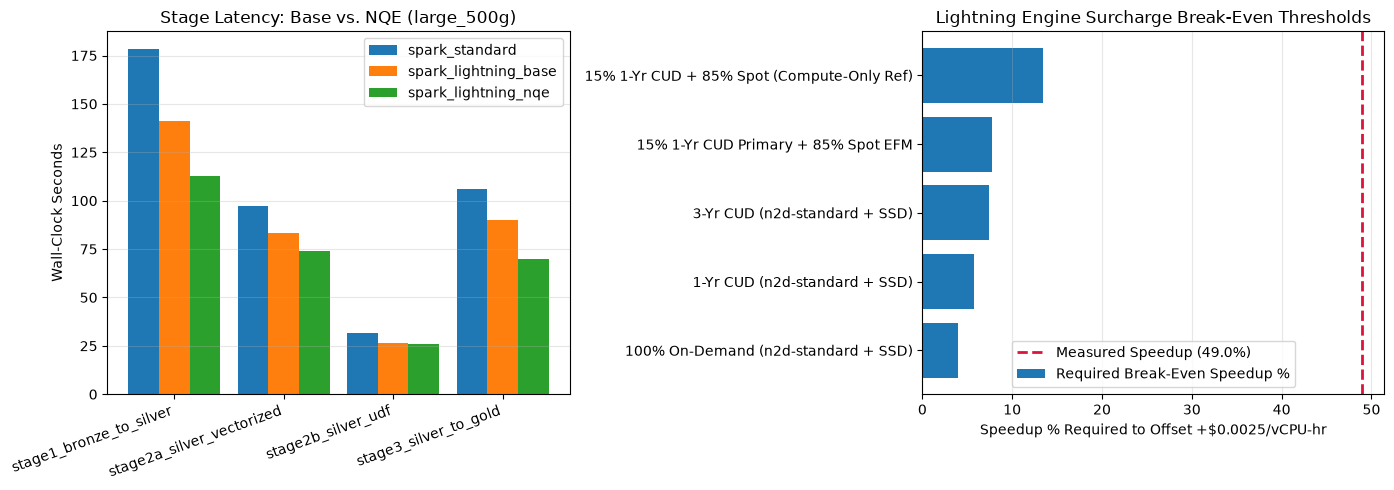

In [9]:
# Discount multipliers aligned identically with notebooks/04_benchmark_summary_and_tco.ipynb PRICING_CONFIG
# applied onto canonical list rates imported from scripts.metrics_helper.US_LIST_RATES.
PRICING_TIER_MULTIPLIERS = {
    "on_demand": {"compute_ram": 1.00, "local_ssd": 1.00},
    "cud_1yr": {"compute_ram": 0.63, "local_ssd": 0.63},
    "cud_3yr": {"compute_ram": 0.45, "local_ssd": 0.45},
    "spot": {"compute_ram": 0.35, "local_ssd": 0.66},
}

STAGE_ORDER = [
    "stage1_bronze_to_silver",
    "stage2a_silver_vectorized",
    "stage2b_silver_udf",
    "stage3_silver_to_gold",
]


def resolve_worker_hourly_rates(
    worker_machine_type: str = WORKER_MACHINE_TYPE,
    worker_vcpus_per_node: int = WORKER_VCPUS_PER_NODE,
    num_worker_local_ssds: int = NUM_WORKER_LOCAL_SSDS,
) -> tuple[list[tuple[str, float]], float]:
    '''Derive worker $/vCPU-hr pricing profiles from scripts.metrics_helper.US_LIST_RATES.'''
    parts = worker_machine_type.strip().split("-")
    family = f"{parts[0]}-{parts[1]}" if len(parts) >= 2 else str(US_LIST_RATES["default_machine_family"])
    if family not in US_LIST_RATES["gce_vcpu_hr_by_family"]:
        family = str(US_LIST_RATES["default_machine_family"])

    list_vcpu_hr = float(US_LIST_RATES["gce_vcpu_hr_by_family"][family])
    list_ram_gb_hr = float(US_LIST_RATES["gce_ram_gb_hr_by_family"][family])
    ram_per_vcpu = float(US_LIST_RATES["gce_ram_gb_per_vcpu_by_family"][family])
    list_compute_ram_vcpu_hr = list_vcpu_hr + (ram_per_vcpu * list_ram_gb_hr)

    list_ssd_per_disk_hr = (
        float(US_LIST_RATES["local_ssd_gb_per_disk"])
        * float(US_LIST_RATES["local_ssd_usd_per_gb_month"])
        / float(US_LIST_RATES["hours_per_month"])
    )
    list_ssd_vcpu_hr = (float(num_worker_local_ssds) * list_ssd_per_disk_hr) / float(max(1, worker_vcpus_per_node))

    dp_mgmt_vcpu_hr = float(US_LIST_RATES["dataproc_gce_fee_per_vcpu_hr"])
    lgt_surcharge_vcpu_hr = float(US_LIST_RATES["dataproc_lightning_surcharge_per_vcpu_hr"])

    def _tier_total(tier: str, include_overhead: bool = True) -> float:
        m = PRICING_TIER_MULTIPLIERS[tier]
        compute_part = list_compute_ram_vcpu_hr * m["compute_ram"]
        if not include_overhead:
            return compute_part
        ssd_part = list_ssd_vcpu_hr * m["local_ssd"]
        return compute_part + ssd_part + dp_mgmt_vcpu_hr

    efm_compute_only = (0.15 * _tier_total("cud_1yr", include_overhead=False)) + (
        0.85 * _tier_total("spot", include_overhead=False)
    )
    efm_full = (0.15 * _tier_total("cud_1yr")) + (0.85 * _tier_total("spot"))

    profiles = [
        (f"100% On-Demand ({family} + SSD)", _tier_total("on_demand")),
        (f"1-Yr CUD ({family} + SSD)", _tier_total("cud_1yr")),
        (f"3-Yr CUD ({family} + SSD)", _tier_total("cud_3yr")),
        ("15% 1-Yr CUD Primary + 85% Spot EFM", efm_full),
        ("15% 1-Yr CUD + 85% Spot (Compute-Only Ref)", efm_compute_only),
    ]
    return profiles, lgt_surcharge_vcpu_hr


def compute_stage2b_penalty(records: list[dict[str, Any]]) -> pd.DataFrame | None:
    '''Compare Stage 2A vectorized vs Stage 2B @F.udf normalized for sample_fraction.'''
    by_eng_stage = {(r["engine_variant"], r["stage_id"]): r for r in records}
    rows: list[dict[str, Any]] = []
    for engine in ("spark_lightning_base", "spark_lightning_nqe"):
        r2a = by_eng_stage.get((engine, "stage2a_silver_vectorized"))
        r2b = by_eng_stage.get((engine, "stage2b_silver_udf"))
        if not r2a or not r2b:
            continue
        frac = float(r2b.get("sample_fraction", 1.0) or 1.0)
        w2a = float(r2a["wall_clock_sec"])
        w2b = float(r2b["wall_clock_sec"])
        v2a = float(r2a.get("vcpu_seconds") or (w2a * TOTAL_WORKER_VCPUS))
        v2b = float(r2b.get("vcpu_seconds") or (w2b * TOTAL_WORKER_VCPUS))

        norm_w2b = w2b / frac
        norm_v2b = v2b / frac
        rows.append(
            {
                "engine_variant": engine,
                "stage2a_wall_sec": round(w2a, 2),
                "stage2b_raw_wall_sec": round(w2b, 2),
                "stage2b_sample_fraction": frac,
                "stage2b_norm_full_wall_sec": round(norm_w2b, 2),
                "raw_slowdown_x": round(w2b / max(w2a, 1e-6), 2),
                "normalized_slowdown_x": round(norm_w2b / max(w2a, 1e-6), 2),
                "stage2a_vcpu_sec": round(v2a, 2),
                "stage2b_norm_vcpu_sec": round(norm_v2b, 2),
                "vcpu_sec_penalty_pct": round(((norm_v2b - v2a) / max(v2a, 1e-6)) * 100.0, 1),
                "nqe_fallback_note": r2b.get("nqe_fallback_note", ""),
            }
        )
    return pd.DataFrame(rows) if rows else None


def load_optional_standard_baseline() -> dict[str, dict[str, Any]]:
    '''Load latest spark_standard run for SCALE_PRESET from live JSONL if already recorded.'''
    if not LIVE_JSONL_PATH.is_file():
        return {}
    loaded = load_benchmark_runs(live_path=LIVE_JSONL_PATH)
    df_all = loaded if isinstance(loaded, pd.DataFrame) else pd.DataFrame(loaded)
    if df_all.empty:
        return {}
    sub = df_all[
        (df_all["scale_preset"] == SCALE_PRESET) & (df_all["engine_variant"] == "spark_standard")
    ].copy()
    if sub.empty:
        return {}
    sub = sub.sort_values("end_epoch_sec").drop_duplicates(subset=["stage_id"], keep="last")
    return {row["stage_id"]: row.to_dict() for _, row in sub.iterrows()}


def build_speedup_table(
    base_recs: list[dict[str, Any]],
    nqe_recs: list[dict[str, Any]],
    std_by_stage: dict[str, dict[str, Any]],
    *,
    base_submit_sec: float | None = None,
    nqe_submit_sec: float | None = None,
) -> pd.DataFrame:
    '''Build stage-by-stage speedup table comparing Base, NQE, optional Standard, and submit wall clock.'''
    b_map = {r["stage_id"]: r for r in base_recs}
    n_map = {r["stage_id"]: r for r in nqe_recs}
    rows: list[dict[str, Any]] = []
    for stage_id in [s for s in STAGE_ORDER if s in b_map and s in n_map]:
        bw = float(b_map[stage_id]["wall_clock_sec"])
        nw = float(n_map[stage_id]["wall_clock_sec"])
        bv = float(b_map[stage_id].get("vcpu_seconds") or (bw * TOTAL_WORKER_VCPUS))
        nv = float(n_map[stage_id].get("vcpu_seconds") or (nw * TOTAL_WORKER_VCPUS))
        entry: dict[str, Any] = {
            "stage_id": stage_id,
            "base_wall_sec": round(bw, 2),
            "nqe_wall_sec": round(nw, 2),
            "nqe_vs_base_speedup_x": round(bw / max(nw, 1e-6), 2),
            "nqe_time_reduction_pct": round(((bw - nw) / max(bw, 1e-6)) * 100.0, 1),
            "base_vcpu_sec": round(bv, 2),
            "nqe_vcpu_sec": round(nv, 2),
        }
        if stage_id in std_by_stage:
            sw = float(std_by_stage[stage_id]["wall_clock_sec"])
            entry["std_wall_sec"] = round(sw, 2)
            entry["base_vs_std_speedup_x"] = round(sw / max(bw, 1e-6), 2)
            entry["nqe_vs_std_speedup_x"] = round(sw / max(nw, 1e-6), 2)
        rows.append(entry)

    # End-to-end relational subtotal (Stages 1 + 2A + 3) excluding Stage 2B UDF contrast.
    rel_stages = [s for s in ("stage1_bronze_to_silver", "stage2a_silver_vectorized", "stage3_silver_to_gold") if s in b_map]
    if rel_stages:
        rel_bw = sum(float(b_map[s]["wall_clock_sec"]) for s in rel_stages)
        rel_nw = sum(float(n_map[s]["wall_clock_sec"]) for s in rel_stages)
        rel_bv = sum(
            float(b_map[s].get("vcpu_seconds") or (float(b_map[s]["wall_clock_sec"]) * TOTAL_WORKER_VCPUS))
            for s in rel_stages
        )
        rel_nv = sum(
            float(n_map[s].get("vcpu_seconds") or (float(n_map[s]["wall_clock_sec"]) * TOTAL_WORKER_VCPUS))
            for s in rel_stages
        )
        rel_row: dict[str, Any] = {
            "stage_id": "TOTAL_RELATIONAL_1_2A_3",
            "base_wall_sec": round(rel_bw, 2),
            "nqe_wall_sec": round(rel_nw, 2),
            "nqe_vs_base_speedup_x": round(rel_bw / max(rel_nw, 1e-6), 2),
            "nqe_time_reduction_pct": round(((rel_bw - rel_nw) / max(rel_bw, 1e-6)) * 100.0, 1),
            "base_vcpu_sec": round(rel_bv, 2),
            "nqe_vcpu_sec": round(rel_nv, 2),
        }
        if all(s in std_by_stage for s in rel_stages):
            rel_sw = sum(float(std_by_stage[s]["wall_clock_sec"]) for s in rel_stages)
            rel_row["std_wall_sec"] = round(rel_sw, 2)
            rel_row["base_vs_std_speedup_x"] = round(rel_sw / max(rel_bw, 1e-6), 2)
            rel_row["nqe_vs_std_speedup_x"] = round(rel_sw / max(rel_nw, 1e-6), 2)
        rows.append(rel_row)

    if base_submit_sec and nqe_submit_sec:
        rows.append(
            {
                "stage_id": "CLIENT_SUBMIT_E2E_WALL",
                "base_wall_sec": round(base_submit_sec, 2),
                "nqe_wall_sec": round(nqe_submit_sec, 2),
                "nqe_vs_base_speedup_x": round(base_submit_sec / max(nqe_submit_sec, 1e-6), 2),
                "nqe_time_reduction_pct": round(
                    ((base_submit_sec - nqe_submit_sec) / max(base_submit_sec, 1e-6)) * 100.0, 1
                ),
                "base_vcpu_sec": round(base_submit_sec * TOTAL_WORKER_VCPUS, 2),
                "nqe_vcpu_sec": round(nqe_submit_sec * TOTAL_WORKER_VCPUS, 2),
            }
        )
    return pd.DataFrame(rows)


def compute_breakeven_table(
    measured_nqe_vs_base_speedup_pct: float,
    measured_nqe_vs_std_speedup_pct: float | None = None,
) -> pd.DataFrame:
    '''Evaluate +$0.0025/vCPU-hr Lightning surcharge break-even using US_LIST_RATES.'''
    profiles, lgt_surcharge_vcpu_hr = resolve_worker_hourly_rates()
    rows: list[dict[str, Any]] = []
    measured = (
        measured_nqe_vs_std_speedup_pct
        if measured_nqe_vs_std_speedup_pct is not None
        else measured_nqe_vs_base_speedup_pct
    )
    for name, std_rate in profiles:
        lgt_rate = std_rate + lgt_surcharge_vcpu_hr
        req_speedup_pct = (lgt_surcharge_vcpu_hr / std_rate) * 100.0
        req_time_cut_pct = (lgt_surcharge_vcpu_hr / lgt_rate) * 100.0
        rows.append(
            {
                "pricing_profile": name,
                "std_rate_per_vcpu_hr": round(std_rate, 5),
                "lightning_rate_per_vcpu_hr": round(lgt_rate, 5),
                "surcharge_premium_pct": round(req_speedup_pct, 1),
                "required_breakeven_speedup_pct": round(req_speedup_pct, 1),
                "required_time_reduction_pct": round(req_time_cut_pct, 1),
                "measured_relational_speedup_pct": round(measured, 1),
                "net_cost_positive": measured >= req_speedup_pct,
            }
        )
    return pd.DataFrame(rows)


penalty_df = compute_stage2b_penalty(base_records + nqe_records)
if penalty_df is not None:
    print("=== Stage 2A Vectorized vs. Stage 2B Scalar @F.udf Penalty ===")
    display(penalty_df)
else:
    print("Stage 2B skipped (RUN_PYTHON_UDF_STAGE=false).")

std_baseline = load_optional_standard_baseline()
speedup_df = build_speedup_table(
    base_records,
    nqe_records,
    std_baseline,
    base_submit_sec=base_payload.get("submit_wall_clock_sec"),
    nqe_submit_sec=nqe_payload.get("submit_wall_clock_sec"),
)
print("=== Stage-by-Stage Speedup Summary (In-Cluster Active Timers & Submit Boundary) ===")
if not std_baseline:
    print("(Note: spark_standard baseline not yet in live_runs/benchmark_runs.jsonl for this SCALE_PRESET; showing Base vs NQE.)")
display(speedup_df)

rel_summary = speedup_df[speedup_df["stage_id"] == "TOTAL_RELATIONAL_1_2A_3"].iloc[0]
nqe_vs_base_pct = (float(rel_summary["nqe_vs_base_speedup_x"]) - 1.0) * 100.0
nqe_vs_std_pct = (
    (float(rel_summary["nqe_vs_std_speedup_x"]) - 1.0) * 100.0
    if "nqe_vs_std_speedup_x" in rel_summary and pd.notna(rel_summary["nqe_vs_std_speedup_x"])
    else None
)
breakeven_df = compute_breakeven_table(nqe_vs_base_pct, nqe_vs_std_pct)
print("=== Lightning Engine +$0.0025/vCPU-hr Break-Even Analysis (via scripts.metrics_helper.US_LIST_RATES) ===")
display(breakeven_df)


def plot_lightning_diagnostics(spd_df: pd.DataFrame, brk_df: pd.DataFrame) -> None:
    '''Render stage latency bar chart and break-even speedup threshold comparison.'''
    stage_rows = spd_df[~spd_df["stage_id"].isin({"TOTAL_RELATIONAL_1_2A_3", "CLIENT_SUBMIT_E2E_WALL"})].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    x = range(len(stage_rows))
    width = 0.28 if "std_wall_sec" in stage_rows.columns else 0.36
    if "std_wall_sec" in stage_rows.columns:
        axes[0].bar([i - width for i in x], stage_rows["std_wall_sec"], width=width, label="spark_standard")
        axes[0].bar(x, stage_rows["base_wall_sec"], width=width, label="spark_lightning_base")
        axes[0].bar([i + width for i in x], stage_rows["nqe_wall_sec"], width=width, label="spark_lightning_nqe")
    else:
        axes[0].bar([i - width / 2 for i in x], stage_rows["base_wall_sec"], width=width, label="spark_lightning_base")
        axes[0].bar([i + width / 2 for i in x], stage_rows["nqe_wall_sec"], width=width, label="spark_lightning_nqe")

    axes[0].set_xticks(list(x))
    axes[0].set_xticklabels(stage_rows["stage_id"], rotation=20, ha="right")
    axes[0].set_ylabel("Wall-Clock Seconds")
    axes[0].set_title(f"Stage Latency: Base vs. NQE ({SCALE_PRESET})")
    axes[0].legend()
    axes[0].grid(axis="y", alpha=0.3)

    y_pos = range(len(brk_df))
    axes[1].barh(y_pos, brk_df["required_breakeven_speedup_pct"], label="Required Break-Even Speedup %")
    measured_val = float(brk_df["measured_relational_speedup_pct"].iloc[0])
    axes[1].axvline(
        measured_val,
        color="crimson",
        linestyle="--",
        linewidth=2,
        label=f"Measured Speedup ({measured_val:.1f}%)",
    )
    axes[1].set_yticks(list(y_pos))
    axes[1].set_yticklabels(brk_df["pricing_profile"])
    axes[1].set_xlabel("Speedup % Required to Offset +$0.0025/vCPU-hr")
    axes[1].set_title("Lightning Engine Surcharge Break-Even Thresholds")
    axes[1].legend()
    axes[1].grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_lightning_diagnostics(speedup_df, breakeven_df)